# VPL vs CESS, from the pgm and the DF objective (experiment 2)

`slurm_jobs/DF_wc003_experiments/exp2_vpl_vs_cess.slurm`, run through `experiments/DF_wc003_server_sweep.py`:
the two-stage procedure (LDF siting -> DF sizing) for C_total x Gamma (units, per node = total) x VPL/CESS,
on each grid pair x 4 days. Same figures as `v5/04b_DF_plots`, once per grid pair. The objective is either
each run's **pgm** re-pricing (`post_solve_pgm_objective`), the **model**'s own (DF, as solved), or both --
`PLOT_OBJECTIVE`. `OBJECTIVE_TERM` picks the term: `"total"` (the full objective, `w_current * sum(ell)` included) or
`"congestion"` (`current_congestion_objective` alone).
The no-storage point (C_total = 0) is experiment 2's own baseline run of that grid pair.

- normalized objective = objective / objective without storage (same grid pair)
- parity (per grid pair, Gamma, C_total) = (worst - obj) / (worst - best), worst = no storage, best = the better
  of VPL/CESS, exactly as 04b. Not clipped.
- under `PLOT_OBJECTIVE = "both"` colour/marker shape is VPL/CESS, linestyle is Gamma, and the **marker fill**
  is the objective: filled = pgm, hollow = model.
- the secondary x-axis is C_total as a share of that grid pair's average daily demand, sum_n |p_n| per day
  (`vr.avg_daily_abs_demand_MWh`; 04b's constant was [C0,S0] x 4 days).

In [1]:
print("Cell Started")
from IPython.display import clear_output, display

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, str(Path.cwd().parent))   # paper_companion/: vpl_results.py, shared by every experiment
import vpl_results as vr   # the run reader for slurm_jobs/DF_wc003_experiments/

print("Cell Finished")
clear_output()
pd.set_option("display.width", 250)

In [2]:
#USED_GRIDS = ["C0S0", "S0R0", "R0C0"]   # only these grid pairs are loaded, tabled and plotted
USED_GRIDS = ["C0S0"]  
GRIDS = vr.grid_pairs(USED_GRIDS)           # as the "grids" column spells them ("C0,S0", ...)

# Where the sweep folders (as the scripts wrote them, job_<id>/ subfolders and all) were copied.
RESULTS = Path(r"C:\Users\VerdaasdonkF\OneDrive - University of Twente\Desktop\results\v5_reweighted_261022")
EXP1 = RESULTS / "DF_exp1_two_stage_validation" / "DF_exp1_two_stage_validation"
EXP2 = RESULTS / "DF_exp2_vpl_vs_cess" / "DF_exp2_vpl_vs_cess"                     # + one baseline per grid pair
EXP3 = RESULTS / "DF_exp3_slack_value" / "DF_exp3_slack_value"

# which objective the curves show: "pgm" (AC re-pricing), "model" (DF, as solved) or "both"
PLOT_OBJECTIVE = "both"
OBJECTIVES = vr.objective_columns(PLOT_OBJECTIVE)

# which term: "total" (the full objective, w_current * sum(ell) included) or "congestion" (current_congestion_objective alone)
OBJECTIVE_TERM = "total"

In [3]:
GRIDS

('C0,S0',)

In [4]:
df2 = vr.select_term(vr.load(EXP2, GRIDS), OBJECTIVE_TERM)
runs = vr.two_stage(df2)
base = vr.one_per(df2[df2["phase"] == "baseline"], ["grids"])
print("w_current (DF runs):", sorted(df2.loc[df2["physics"] == "DistFlow", "w_current"].unique()))
display(base[["run", "status", "objective", "pgm_objective"]])
runs.groupby(["grids", "vcc", "units"]).size().unstack()

w_current (DF runs): [np.float64(0.03)]


,run,status,objective,pgm_objective
grids,,,,
"C0,S0",exp_90_baseline_C0-S0_20261021_223836,OPTIMAL,9.653402,9.711196


units        5   10  20
grids vcc              
C0,S0 False   5   5   5
      True    5   5   5

In [5]:
columns_of_interest = ["run", "grids", "days", "units", "C_base", "C_total", "vcc", "status", "mip_gap", "time_s",
                       "objective", "pgm_objective", "n_sites", "gamma_n"]
slim_df = runs[columns_of_interest].rename(columns={"units": "max_units_total", "vcc": "use_virtual_cable_constraint"})

# C_total = 0: the grid pair's baseline, once per (Gamma, vcc) so every line starts there
zero = pd.DataFrame([{"run": b["run"], "grids": g, "days": b["days"], "max_units_total": u, "C_base": 0.0,
                      "C_total": 0.0, "use_virtual_cable_constraint": v, "status": b["status"],
                      "mip_gap": b["mip_gap"], "time_s": b["wall_time_s"], "objective": b["objective"],
                      "pgm_objective": b["pgm_objective"], "n_sites": 0, "gamma_n": {}}
                     for g, b in base.iterrows()
                     for u in sorted(slim_df["max_units_total"].unique()) for v in (True, False)])
slim_df = pd.concat([zero, slim_df], ignore_index=True)

for col in ("pgm_objective", "objective"):
    slim_df[f"normalized_{col}"] = slim_df[col] / slim_df["grids"].map(base[col])

In [6]:
group_by = ["grids", "max_units_total", "C_total"]
split_by = "use_virtual_cable_constraint"


def add_parity(slim_df, normalize_by):
    # 04b's parity: worst over the grid pair (= no storage), best per (grids, Gamma, C_total) over VPL/CESS
    worst = slim_df.groupby("grids")[normalize_by].transform("max")
    best = slim_df.groupby(group_by)[normalize_by].transform("min")
    slim_df[f"{normalize_by}_parity"] = (worst - slim_df[normalize_by]) / (worst - best)
    slim_df.loc[slim_df["C_total"] == 0, f"{normalize_by}_parity"] = 1
    return slim_df


slim_df = add_parity(slim_df, "pgm_objective")
slim_df = add_parity(slim_df, "objective")

for grids in GRIDS:
    print(grids)
    with pd.option_context("display.float_format", "{:.3f}".format):
        display(slim_df[slim_df["grids"] == grids].pivot_table(
            index="C_total", columns=["max_units_total", split_by],
            values=[f"normalized_{o}" for o in OBJECTIVES] + [f"{o}_parity" for o in OBJECTIVES]))

C0,S0


normalized_objective                               normalized_pgm_objective                    ... objective_parity                   pgm_objective_parity                              
max_units_total                                5           10          20                             5           10        ...               10          20                         5           10          20      
use_virtual_cable_constraint                False True  False True  False True                     False True  False True   ...            False True  False True                 False True  False True  False True 
C_total                                                                                                                     ...                                                                                      
0.000                                       1.000 1.000 1.000 1.000 1.000 1.000                    1.000 1.000 1.000 1.000  ...            1.000 1.000 1.000 1.000                1.000 1.000 1.000 1.000 1.000 1.000
1.000                                       0.887 0.910 0.887 0.900 0.885 0.899                    0.888 0.911 0.888 0.901  ...            1.000 0.886 1.000 0.885                1.000 0.796 1.000 0.884 1.000 0.884
2.500                                       0.791 0.840 0.789 0.827 0.787 0.817                    0.793 0.842 0.791 0.829  ...            1.000 0.822 1.000 0.860                1.000 0.762 1.000 0.821 1.000 0.859
5.000                                       0.720 0.756 0.706 0.745 0.704 0.737                    0.723 0.758 0.709 0.747  ...            1.000 0.868 1.000 0.889                1.000 0.872 1.000 0.869 1.000 0.891
10.000                                      0.582 0.683 0.582 0.643 0.568 0.631                    0.585 0.686 0.583 0.646  ...            1.000 0.854 1.000 0.855                1.000 0.757 1.000 0.850 1.000 0.853
20.000                                      0.435 0.579 0.414 0.522 0.410 0.510                    0.432 0.582 0.412 0.523  ...            1.000 0.816 1.000 0.831                1.000 0.735 1.000 0.812 1.000 0.826

[6 rows x 24 columns]

In [7]:
# runs that did not close: their numbers are incumbents
with pd.option_context("display.float_format", "{:.4f}".format):
    display(slim_df[slim_df["status"] != "OPTIMAL"][["run", "status", "mip_gap", "time_s"]])

,run,status,mip_gap,time_s


In [8]:
STYLE = {
    # --- figure ---
    "figsize": (6.0, 4.5),             # inches, legend included; on screen this is figsize * inline_dpi pixels
    "inline_dpi": 100,
    "save_dpi": 300,
    "font_size": 9,
    "font_family": "sans-serif",
    "save_dir": Path("figs"),          # None -> don't save
    "save_formats": ("eps", "png"),
    "show_title": False,               # the grid pair ("C0 + S0"), above the axes

    # --- series: one entry per use_virtual_cable_constraint value ---
    "vcc": {
        True:  {"label": "VPL",  "color": "tab:blue", "marker": "D", "markersize": 4.5, "zorder": 3},
        False: {"label": "CESS", "color": "tab:red",  "marker": "o", "markersize": 5,   "zorder": 2},
    },
    "vcc_order": (True, False),
    "parity_vcc": (True,),             # which vcc values the parity plot shows

    # --- linestyle: one entry per max_units_total value ---
    "units": {
        5:  {"linestyle": "-"},
        10: {"linestyle": "--"},
        20: {"linestyle": ":"},
    },
    "units_label": r"$\Gamma = {n}$",
    "units_legend_color": "0.3",

    # --- objective: linestyle is taken by Gamma, so under PLOT_OBJECTIVE = "both" they differ in marker fill ---
    "objectives": {
        "pgm_objective": {"label": "pgm AC replay",   "hollow": False, "alpha": 1.0},
        "objective":     {"label": "as solved (DF)",  "hollow": True,  "alpha": 0.7},
    },

    # --- shared line/marker settings ---
    "linewidth": 1.3,
    "alpha": 1.0,
    "markeredgecolor": "white",
    "markeredgewidth": 0.5,
    "hollow_markeredgewidth": 1.0,

    # --- axes ---
    "xlabel": r"Total storage capacity $C^{\mathrm{total}}$ [MWh]",
    "ylabel_normalized": "Normalized objective [-]",
    "ylabel_parity": "Objective parity [-]\n (VPL compared against CESS)",
    "parity_ylim": None,               # None -> autoscale
    "grid": True,
    "grid_kwargs": {"linestyle": "-", "linewidth": 0.4, "alpha": 0.4},
    "hide_spines": ("top", "right"),

    # --- secondary x-axis ---
    "secondary_x": True,
    "secondary_xlabel": r"$C^\text{total}$ is share of avg. daily grid demand [%]",
    "secondary_x_fmt": "{x:.0f}%",

    # --- legend: shared look, then placement + columns per figure (merged over legend_kwargs) ---
    # outside, to the right:  {"loc": "upper left", "bbox_to_anchor": (1.02, 1.0)}
    # inside, top right:      {"loc": "upper right"}
    # ncol > 1 pads each group (VPL/CESS, Gamma, objectives) to the longest, so ncol = number of groups
    # gives one column per group; at ncol = 1 groups are stacked, split by a blank row (legend_separate_groups)
    "legend_kwargs": {"frameon": True, "facecolor": "white", "framealpha": 1.0,
                      "edgecolor": "lightgrey", "fancybox": False,
                      "fontsize": 8, "handlelength": 2.5},
    "legend_normalized": {"loc": "upper right", "ncol": 2},
    "legend_parity": {"loc": "upper right", "ncol": 1},
    "legend_separate_groups": True,
}

plt.rcParams.update({
    "font.size": STYLE["font_size"],
    "font.family": STYLE["font_family"],
    "figure.dpi": STYLE["inline_dpi"],
    "savefig.dpi": STYLE["save_dpi"],
})

CURVE_LEVELS = ("series", "Gamma", "objective")   # the legend entries a column of VALUES[...] is one combination of
VALUES = {}                                        # figure name -> its numbers (also <name>.csv beside the figure)


In [9]:
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, StrMethodFormatter


def style_axes(ax, xlabel, ylabel, style=STYLE):
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if style["grid"]:
        ax.grid(True, **style["grid_kwargs"])
        ax.set_axisbelow(True)
    for spine in style["hide_spines"]:
        ax.spines[spine].set_visible(False)


def add_demand_axis(ax, reference_MWh, style=STYLE):
    """Top x-axis showing the bottom axis (MWh) as % of reference_MWh. No-op if style["secondary_x"] is False."""
    if not style["secondary_x"]:
        return None
    secax = ax.secondary_xaxis(
        "top",
        functions=(lambda c: 100 * c / reference_MWh, lambda pct: pct * reference_MWh / 100),
    )
    secax.set_xlabel(style["secondary_xlabel"])
    secax.xaxis.set_major_locator(MaxNLocator(nbins="auto", steps=[1, 2, 5, 10]))
    secax.xaxis.set_major_formatter(StrMethodFormatter(style["secondary_x_fmt"]))
    return secax


def save_fig(fig, name, style=STYLE):
    if style["save_dir"] is None:
        return
    style["save_dir"].mkdir(parents=True, exist_ok=True)
    for fmt in style["save_formats"]:
        fig.savefig(style["save_dir"] / f"{name}.{fmt}", bbox_inches="tight")


def save_values(df, name, style=STYLE):
    """The figure's numbers (vr.curves_frame) as <name>.csv beside the figure."""
    if style["save_dir"] is None:
        return
    style["save_dir"].mkdir(parents=True, exist_ok=True)
    df.to_csv(style["save_dir"] / f"{name}.csv")


def marker_kwargs(color, hollow, style=STYLE):
    if hollow:
        return {"markerfacecolor": "white", "markeredgecolor": color, "markeredgewidth": style["hollow_markeredgewidth"]}
    return {"markerfacecolor": color, "markeredgecolor": style["markeredgecolor"], "markeredgewidth": style["markeredgewidth"]}


def plot_by_vcc_and_units(ax, data, x, y, style=STYLE, vcc_values=None, vcc_col=split_by, units_col="max_units_total",
                          alpha=None, hollow=False):
    """One line per (vcc, max_units_total): colour+marker from style["vcc"], linestyle from style["units"].
    Repeated runs at the same x are averaged. Returns the lines drawn, {(VPL/CESS label, Gamma): Series}."""
    data = data.copy()
    data[y] = data[y].astype(float)
    vcc_values = style["vcc_order"] if vcc_values is None else vcc_values
    alpha = style["alpha"] if alpha is None else alpha
    curves = {}
    for vcc in vcc_values:
        vs = style["vcc"][vcc]
        for n_units, us in style["units"].items():
            sub = data[(data[vcc_col] == vcc) & (data[units_col] == n_units)]
            if sub.empty:
                continue
            line = sub.groupby(x)[y].mean().sort_index()
            ax.plot(
                line.index, line.values,
                color=vs["color"], marker=vs["marker"], markersize=vs["markersize"], zorder=vs["zorder"],
                linestyle=us["linestyle"], linewidth=style["linewidth"], alpha=alpha,
                **marker_kwargs(vs["color"], hollow, style),
            )
            curves[(vs["label"], n_units)] = line
    return curves


def plot_objectives(ax, data, y, objectives=OBJECTIVES, style=STYLE, **kwargs):
    """plot_by_vcc_and_units once per objective column; y is a template like "normalized_{obj}".
    A single objective is drawn filled and opaque. Returns the lines drawn, {(VPL/CESS, Gamma, objective): Series}."""
    curves = {}
    for obj in objectives:
        os_ = style["objectives"][obj] if len(objectives) > 1 else {"alpha": style["alpha"], "hollow": False}
        drawn = plot_by_vcc_and_units(ax, data, x="C_total", y=y.format(obj=obj), alpha=os_["alpha"],
                                      hollow=os_["hollow"], style=style, **kwargs)
        curves.update({(*key, style["objectives"][obj]["label"]): line for key, line in drawn.items()})
    return curves


def add_legend(ax, style=STYLE, show_vcc=True, objectives=OBJECTIVES, legend_kwargs=None):
    """VPL/CESS as colour+marker (no line), then Gamma as linestyle (no marker), then (if more than one)
    the objectives as marker fill. legend_kwargs (e.g. style["legend_parity"]) is merged over style["legend_kwargs"]."""
    kwargs = {**style["legend_kwargs"], **(legend_kwargs or {})}
    groups = []
    if show_vcc:
        groups.append([
            Line2D([], [], color=style["vcc"][v]["color"], marker=style["vcc"][v]["marker"],
                   markersize=style["vcc"][v]["markersize"], linestyle="none", label=style["vcc"][v]["label"],
                   **marker_kwargs(style["vcc"][v]["color"], False, style))
            for v in style["vcc_order"]
        ])
    groups.append([
        Line2D([], [], color=style["units_legend_color"], linestyle=s["linestyle"],
               linewidth=style["linewidth"], label=style["units_label"].format(n=n))
        for n, s in style["units"].items()
    ])
    if len(objectives) > 1:
        groups.append([
            Line2D([], [], color="0.3", marker="o", markersize=5, linestyle="none",
                   alpha=style["objectives"][o]["alpha"], label=style["objectives"][o]["label"],
                   **marker_kwargs("0.3", style["objectives"][o]["hollow"], style))
            for o in objectives
        ])

    blank = lambda: Line2D([], [], linestyle="none", label=" ")
    handles = []
    if kwargs.get("ncol", 1) > 1:
        # the legend fills column by column: pad every group to the same height so each starts a new column
        rows = max(len(g) for g in groups)
        for g in groups:
            handles += g + [blank() for _ in range(rows - len(g))]
    else:
        for i, g in enumerate(groups):
            if i and style["legend_separate_groups"]:
                handles.append(blank())
            handles += g
    return ax.legend(handles=handles, **kwargs)


def grid_figure(grids, style=STYLE):
    fig, ax = plt.subplots(figsize=style["figsize"])
    if style["show_title"]:
        ax.set_title(grids.replace(",", " + "), fontsize=style["font_size"])
    return fig, ax

removed 1 edges to remove cycles

removed 1 edges to remove cycles

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


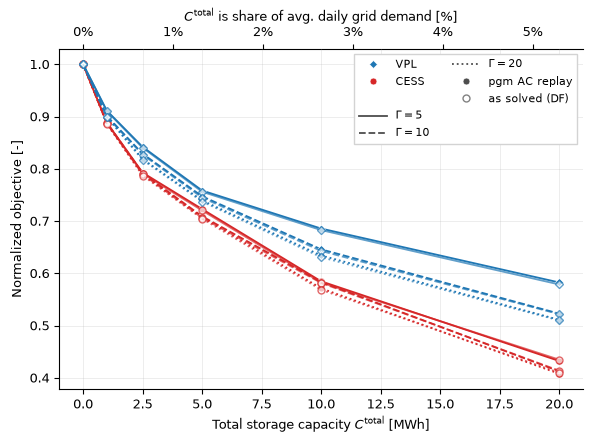

01_normalized_objective_C0-S0_both_total

series                                                  VPL                                      CESS                                        VPL                                         CESS                              
Gamma                                                    5             10            20            5             10            20             5              10             20             5              10             20
objective                                     pgm AC replay pgm AC replay pgm AC replay pgm AC replay pgm AC replay pgm AC replay as solved (DF) as solved (DF) as solved (DF) as solved (DF) as solved (DF) as solved (DF)
C_total [MWh] C_total [% of avg daily demand]                                                                                                                                                                              
0.0           0.000000                             1.000000      1.000000      1.000000      1.000000      1.000000      1.000000       1.000000       1.000000       1.000000       1.000000       1.000000       1.000000
1.0           0.264762                             0.911029      0.901074      0.899846      0.888211      0.888057      0.886712       0.909917       0.899698       0.898586       0.886954       0.886794       0.885446
2.5           0.661906                             0.841927      0.828667      0.818639      0.792604      0.791425      0.788959       0.840208       0.826900       0.816841       0.790635       0.789409       0.786919
5.0           1.323811                             0.758368      0.747286      0.739414      0.722874      0.709030      0.707460       0.755949       0.744766       0.737221       0.720190       0.706000       0.704420
10.0          2.647623                             0.685589      0.645825      0.634108      0.584625      0.583259      0.571182       0.682598       0.642782       0.630783       0.582104       0.581526       0.568288
20.0          5.295245                             0.582426      0.522797      0.510940      0.432130      0.412394      0.407724       0.578554       0.521684       0.509684       0.434724       0.413660       0.409931

In [10]:
for grids in GRIDS:
    data = slim_df[slim_df["grids"] == grids]
    fig, ax = grid_figure(grids)
    curves = plot_objectives(ax, data, y="normalized_{obj}")
    style_axes(ax, STYLE["xlabel"], STYLE["ylabel_normalized"])
    reference_MWh = vr.avg_daily_abs_demand_MWh(grids, int(data["days"].iloc[0]))
    add_demand_axis(ax, reference_MWh)
    add_legend(ax, legend_kwargs=STYLE["legend_normalized"])
    fig.tight_layout()
    name = f"01_normalized_objective_{grids.replace(',', '-')}_{PLOT_OBJECTIVE}_{OBJECTIVE_TERM}"
    save_fig(fig, name)
    VALUES[name] = vr.curves_frame(curves, CURVE_LEVELS, reference_MWh=reference_MWh)
    save_values(VALUES[name], name)
    plt.show()
    print(name)
    display(VALUES[name])

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


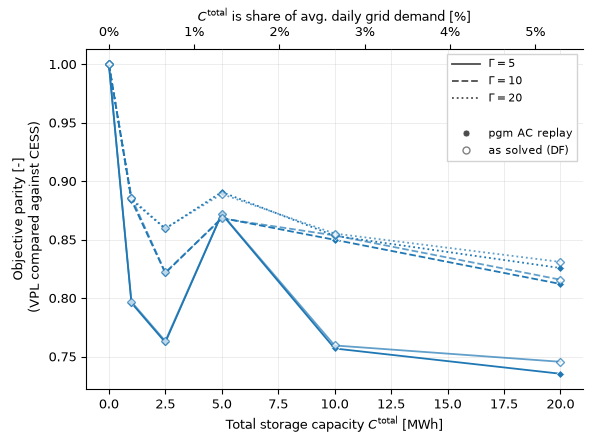

01_objective_parity_C0-S0_both_total

series                                                  VPL                                                                         
Gamma                                                    5             10            20             5              10             20
objective                                     pgm AC replay pgm AC replay pgm AC replay as solved (DF) as solved (DF) as solved (DF)
C_total [MWh] C_total [% of avg daily demand]                                                                                       
0.0           0.000000                             1.000000      1.000000      1.000000       1.000000       1.000000       1.000000
1.0           0.264762                             0.795883      0.883716      0.884062       0.796869       0.886015       0.885288
2.5           0.661906                             0.762181      0.821443      0.859367       0.763224       0.821972       0.859575
5.0           1.323811                             0.871920      0.868520      0.890771       0.872200       0.868143       0.889029
10.0          2.647623                             0.756934      0.849869      0.853257       0.759523       0.853621       0.855240
20.0          5.295245                             0.735333      0.812114      0.825730       0.745558       0.815767       0.830947

In [11]:
for grids in GRIDS:
    data = slim_df[slim_df["grids"] == grids]
    fig, ax = grid_figure(grids)
    curves = plot_objectives(ax, data, y="{obj}_parity", vcc_values=STYLE["parity_vcc"])
    style_axes(ax, STYLE["xlabel"], STYLE["ylabel_parity"])
    if STYLE["parity_ylim"] is not None:
        ax.set_ylim(STYLE["parity_ylim"])
    reference_MWh = vr.avg_daily_abs_demand_MWh(grids, int(data["days"].iloc[0]))
    add_demand_axis(ax, reference_MWh)
    add_legend(ax, show_vcc=False, legend_kwargs=STYLE["legend_parity"])
    fig.tight_layout()
    name = f"01_objective_parity_{grids.replace(',', '-')}_{PLOT_OBJECTIVE}_{OBJECTIVE_TERM}"
    save_fig(fig, name)
    VALUES[name] = vr.curves_frame(curves, CURVE_LEVELS, reference_MWh=reference_MWh)
    save_values(VALUES[name], name)
    plt.show()
    print(name)
    display(VALUES[name])